<a href="https://colab.research.google.com/github/hjmohamedbilal/movies-dataset/blob/main/MohamedBilalHJExperiment6BTDS332.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Experiment 6: Understanding Probability Distributions with Python

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
# Use a fixed seed so the random samples are reproducible.
# Re-running this notebook with the same code should generate the same samples.
np.random.seed(42)
print("Libraries imported successfully.")

Libraries imported successfully.


1. Normal Distribution

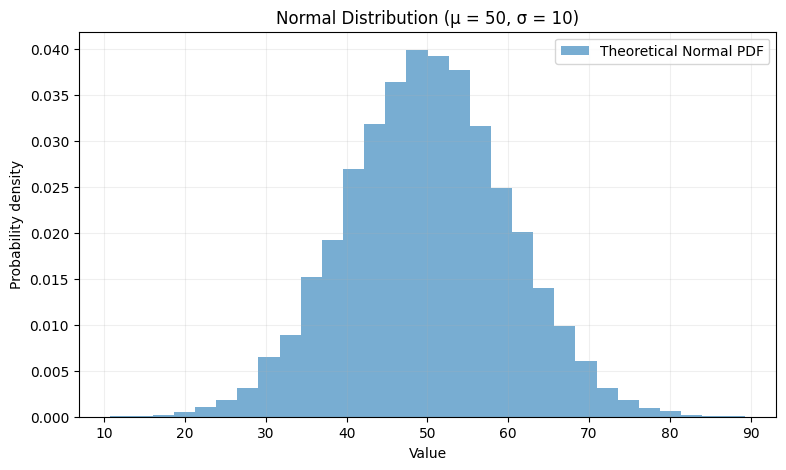

Sample mean: 49.98
Sample standard deviation: 10.03


In [2]:
# Parameters of the Normal distribution
mu = 50 # Mean: the centre of the distribution
sigma = 10 # Standard deviation: the spread of the values
sample_size = 10_000
# Generate random observations from a Normal distribution
data_normal = np.random.normal(loc=mu, scale=sigma, size=sample_size)
# Point where we calculate the theoretical PDF
x_normal = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 500)
# Theoretical Normal probability density function (PDF)
pdf_normal = (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(
    -0.5 * ((x_normal - mu) / sigma) ** 2
)
plt.figure(figsize=(9, 5))
plt.hist(data_normal, bins=30, density=True, alpha=0.6,
         label="Theoretical Normal PDF")
plt.title("Normal Distribution (μ = 50, σ = 10)")
plt.xlabel("Value")
plt.ylabel("Probability density")
plt.legend()
plt.grid(alpha=0.2)
plt.show()
print(f"Sample mean: {np.mean(data_normal):.2f}")
print(f"Sample standard deviation: {np.std(data_normal, ddof=1):.2f}")

2. Binomial Distribution

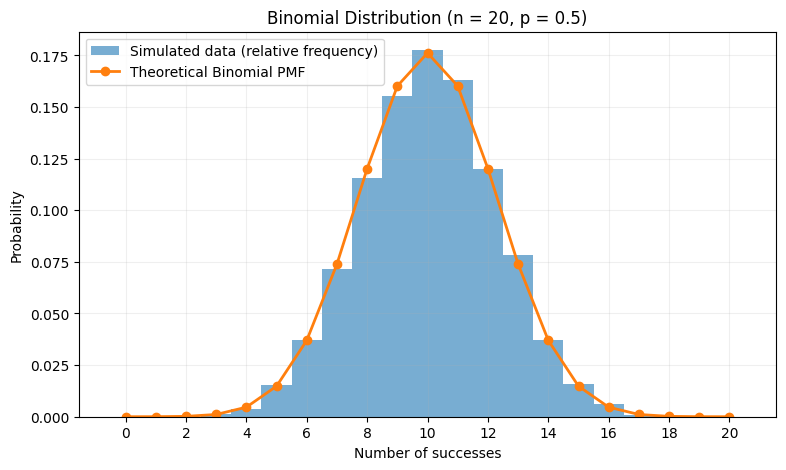

Theoretical mean (n x p): 10.00
Sample mean: 10.05
Theoretical variance (n x p x (1-p)): 5.00


In [3]:
# Parameters of the Binomial distribution
n = 20 # Number of trials
p = 0.5 # Probability of success on each trial
sample_size = 10_000
# Generate random counts of successes across repeated experiments
data_binomial = np.random.binomial(n=n, p=p, size=sample_size)
# All possible numbers of successes: 0, 1, 2, ..., 20
x_binomial = np.arange(0, n + 1)
# Theoretical probability mass function (PMF)
pmf_binomial = np.array([
    math.comb(n, int(x)) * (p ** x) * ((1 - p) ** (n - x))
    for x in x_binomial
])
plt.figure(figsize=(9, 5))
plt.hist(data_binomial,
         bins=np.arange(-0.5, n + 1.5, 1),
         density=True, alpha=0.6,
         label="Simulated data (relative frequency)")
plt.plot(x_binomial, pmf_binomial, "o-",
         linewidth=2, label="Theoretical Binomial PMF")
plt.title(f"Binomial Distribution (n = {n}, p = {p})")
plt.xlabel("Number of successes")
plt.ylabel("Probability")
plt.xticks(np.arange(0, n + 1, 2))
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print(f"Theoretical mean (n x p): {n * p:.2f}")
print(f"Sample mean: {np.mean(data_binomial):.2f}")
print(f"Theoretical variance (n x p x (1-p)): {n * p * (1-p):.2f}")

3. Poisson Distribution

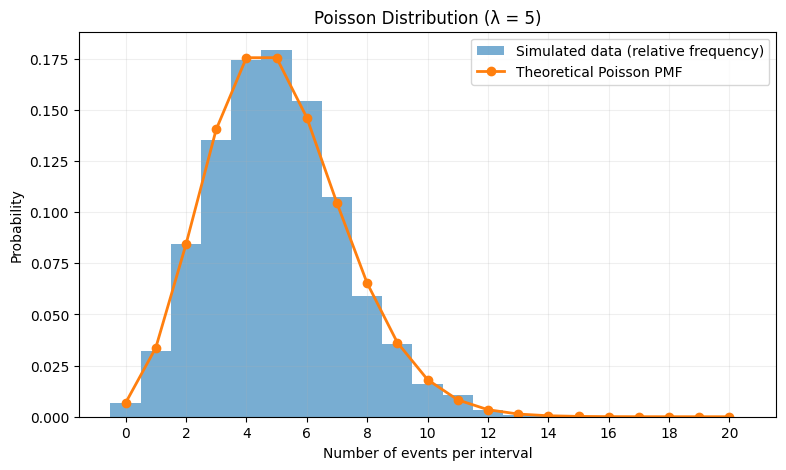

Theoretical mean (lambda): 5.00
Sample mean: 5.01
Theoretical variance (lambda): 5.00
Sample variance: 4.95


In [4]:
# Average event rate per interval
lam = 5
sample_size = 10_000
# Generate random event counts from a Poisson distribution
data_poisson = np.random.poisson(lam=lam, size=sample_size)

# Values at which to calculate theoretical probabilities
# We show 0 through 20; probabilities beyond this range are very small for lambda=5.
x_poisson = np.arange(0, 21)

# Theoretical Poisson probability mass function (PMF)
pmf_poisson = np.array([
    (np.exp(-lam) * lam ** int(x)) / math.factorial(int(x))
    for x in x_poisson
])

plt.figure(figsize=(9, 5))
plt.hist(data_poisson,
         bins=np.arange(-0.5, 21.5, 1),
         density=True, alpha=0.6,
         label="Simulated data (relative frequency)")
plt.plot(x_poisson, pmf_poisson, "o-",
         linewidth=2, label="Theoretical Poisson PMF")
plt.title(f"Poisson Distribution (λ = {lam})")
plt.xlabel("Number of events per interval")
plt.ylabel("Probability")
plt.xticks(np.arange(0, 21, 2))
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print(f"Theoretical mean (lambda): {lam:.2f}")
print(f"Sample mean: {np.mean(data_poisson):.2f}")
print(f"Theoretical variance (lambda): {lam:.2f}")
print(f"Sample variance: {np.var(data_poisson, ddof=1):.2f}")

4. Compare the three distributions

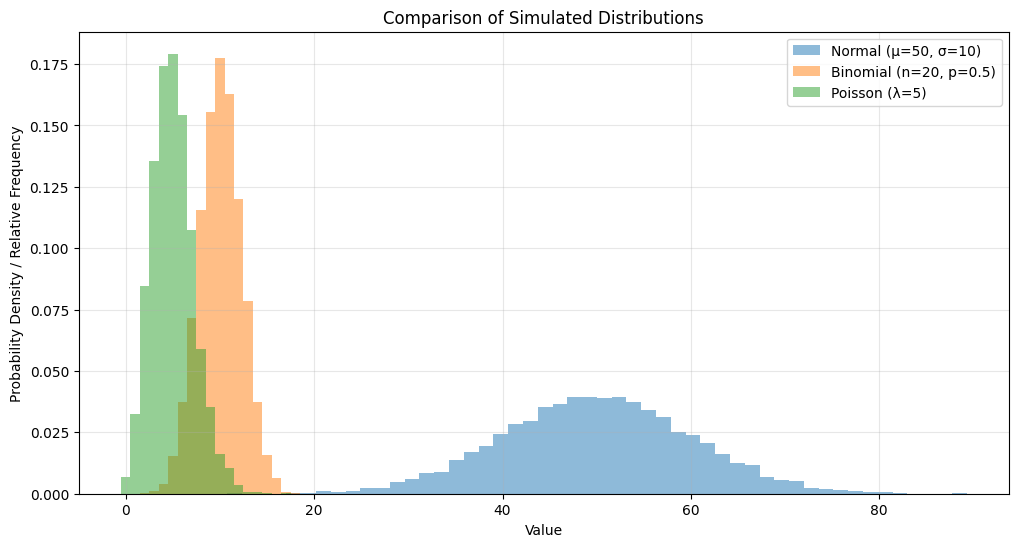

=== Summary Statistics Comparison ===
Normal   | Sample Mean: 49.98  | Sample SD: 10.03
Binomial | Sample Mean: 10.05  | Sample SD: 2.25
Poisson  | Sample Mean: 5.01  | Sample SD: 2.22


In [8]:
plt.figure(figsize=(12, 6))

# Plot normal distribution
plt.hist(data_normal, bins=50, density=True, alpha=0.5, label=f'Normal (μ={mu}, σ={sigma})')

# Plot binomial distribution
plt.hist(data_binomial, bins=np.arange(-0.5, n + 1.5, 1), density=True, alpha=0.5, label=f'Binomial (n={n}, p={p})')

# Plot poisson distribution
plt.hist(data_poisson, bins=np.arange(-0.5, 21.5, 1), density=True, alpha=0.5, label=f'Poisson (λ={lam})')

plt.title("Comparison of Simulated Distributions")
plt.xlabel("Value")
plt.ylabel("Probability Density / Relative Frequency")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Print summary statistics side-by-side for comparison
print("=== Summary Statistics Comparison ===")
print(f"Normal   | Sample Mean: {np.mean(data_normal):.2f}  | Sample SD: {np.std(data_normal, ddof=1):.2f}")
print(f"Binomial | Sample Mean: {np.mean(data_binomial):.2f}  | Sample SD: {np.std(data_binomial, ddof=1):.2f}")
print(f"Poisson  | Sample Mean: {np.mean(data_poisson):.2f}  | Sample SD: {np.std(data_poisson, ddof=1):.2f}")

In [9]:
import pandas as pd

# Calculate metrics for simulated data
sim_means = [np.mean(data_normal), np.mean(data_binomial), np.mean(data_poisson)]
sim_vars = [np.var(data_normal, ddof=1), np.var(data_binomial, ddof=1), np.var(data_poisson, ddof=1)]

# Create a structured comparison dataframe
comparison_data = {
    "Distribution": ["Normal (Continuous)", "Binomial (Discrete)", "Poisson (Discrete)"],
    "Parameters": [
        f"μ = {mu}, σ = {sigma}",
        f"n = {n}, p = {p}",
        f"λ = {lam}"
    ],
    "Theoretical Mean Formula": ["μ", "n * p", "λ"],
    "Theoretical Mean": [mu, n * p, lam],
    "Simulated Mean": [f"{sim_means[0]:.3f}", f"{sim_means[1]:.3f}", f"{sim_means[2]:.3f}"],
    "Theoretical Variance Formula": ["σ²", "n * p * (1 - p)", "λ"],
    "Theoretical Variance": [sigma**2, n * p * (1 - p), lam],
    "Simulated Variance": [f"{sim_vars[0]:.3f}", f"{sim_vars[1]:.3f}", f"{sim_vars[2]:.3f}"]
}

df_compare = pd.DataFrame(comparison_data)
display(df_compare)

,Distribution,Parameters,Theoretical Mean Formula,Theoretical Mean,Simulated Mean,Theoretical Variance Formula,Theoretical Variance,Simulated Variance
0,Normal (Continuous),"μ = 50, σ = 10",μ,50.0,49.979,σ²,100.0,100.694
1,Binomial (Discrete),"n = 20, p = 0.5",n * p,10.0,10.052,n * p * (1 - p),5.0,5.070
2,Poisson (Discrete),λ = 5,λ,5.0,5.012,λ,5.0,4.950
